Загрузите файл Гиперспектр кукурузы.csv (с помощью pd.read_csv).

1. Вычислите аналитическим путем оценки коэффициентов парной линейной регрессии и постройте ее график.
2. Найдите оценки параметров модели парной лиенйной регрессии с использованием метода градиентного спуска. Постройте график.
3. Оцените качество построенных моделей сравнив на графике обучающую выборку и прогнозы.


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [21]:
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0.0
        self.a1 = 0.0

    def predict(self, x):
        return self.a0 + self.a1 * x

    def MSE(self, x, Y):
        return ((Y - self.predict(x)) ** 2).mean()

    def MAE(self, x, Y):
        return abs(Y - self.predict(x)).mean()

    def MAPE(self, x, Y):
        return abs((Y - self.predict(x)) / Y).mean()

    def fit(self, x, Y, alpha=0.0001, epsylon=0.001, max_steps=50000):
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dT_a0 = -2 * sum(Y - self.predict(x))
            dT_a1 = -2 * sum((Y - self.predict(x)) * x)
            self.a0 -= alpha * dT_a0
            self.a1 -= alpha * dT_a1

            new_error = self.MSE(x, Y)
            step += 1
            steps.append(step)
            errors.append(new_error)

            if new_error < epsylon:
                break
        return steps, errors

In [22]:
gipers = pd.read_csv(r"Гиперспектр кукурузы.csv", sep=';')
gipers.head()

,wavelength,Spectr
0,397.32,0.02
1,399.54,0.03
2,401.76,0.03
3,403.98,0.05
4,406.20,0.05


In [23]:
Y = gipers['Spectr']
x = gipers['wavelength']
# mean() - ср. арф.
a1 = ((x - x.mean()) * (Y - Y.mean())).mean()/((x - x.mean()) ** 2).mean()
a0 = Y.mean() - a1*x.mean()
print("Модель линейной регрессии: Y^ = ", a0, " + ", a1, "* x")

Модель линейной регрессии: Y^ =  -0.1834278267811973  +  0.0006681550262486285 * x


In [24]:
# прогнозы
x_space = np.linspace(397, 1000, 2)
print(x_space)
Y_pred = a0 + a1 * x_space
print(Y_pred)

[ 397. 1000.]
[0.08182972 0.4847272 ]


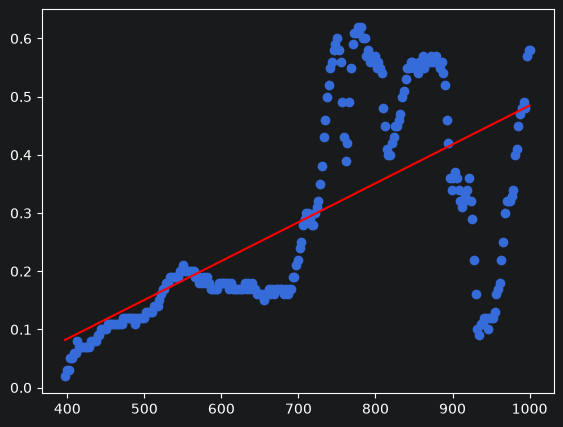

In [25]:
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

In [26]:
regr = SimpleRegression()
print(regr.predict(397))
print(regr.predict(399))
print(regr.predict(401))
print(regr.predict(403))
print(regr.predict(405))
#MSE — это среднеквадратичная ошибка (Mean Squared Error), метрика качества и функция потерь в машинном обучении, которая показывает, насколько сильно прогнозы модели отклоняются от реальных данных
print(regr.MSE(x, Y))

0.0
0.0
0.0
0.0
0.0
0.11187582417582417


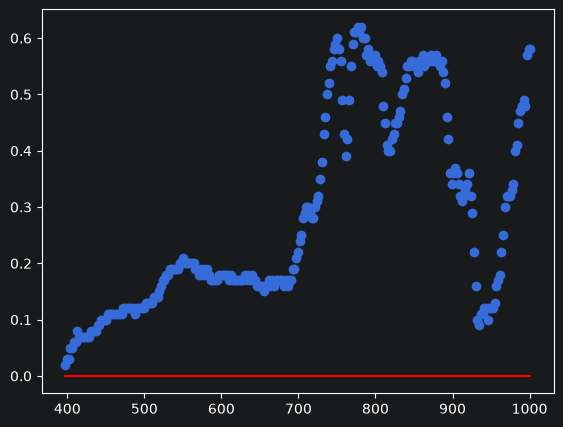

In [27]:
x_space = np.linspace(397, 1000, 2)
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

MSE после первого шага градиентного спуска:  nan


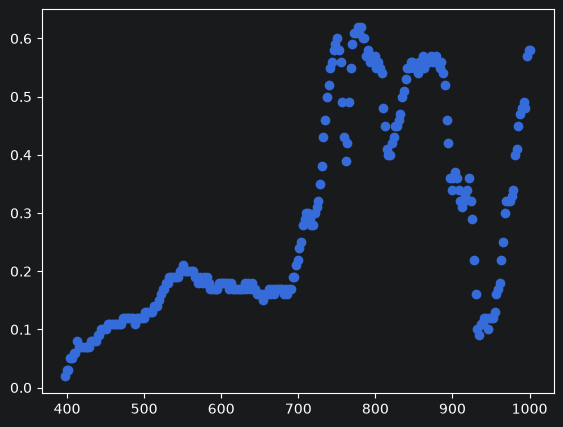

In [28]:
# шаг град спуска
regr = SimpleRegression()
regr.fit(x, Y)
print("MSE после первого шага градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

2 Градиентный спуск


0.16697611888326888
0.16782027324549648
0.16866442760772407
0.16950858196995164
0.17035273633217923
MSE после градиентного спуска: 0.01965363253008138


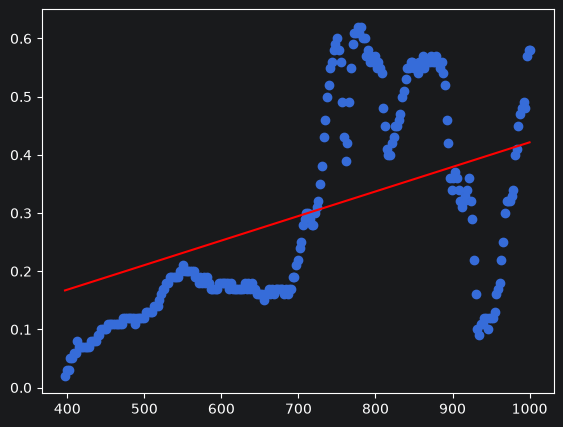

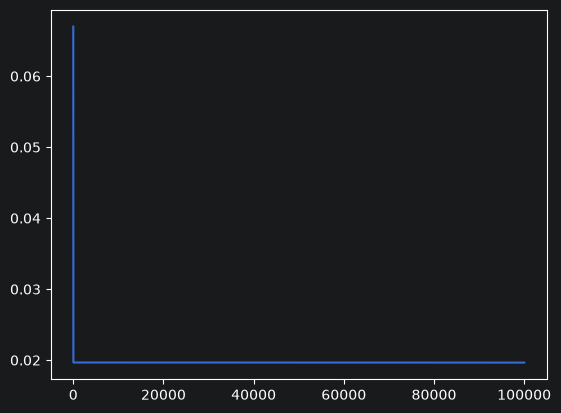

In [29]:
#Выведем график прогнозов и вычислим MSE
regr = SimpleRegression()


steps, errors = regr.fit(x, Y, alpha=1e-9, epsylon=0.0035, max_steps=100000)
print(regr.predict(397))
print(regr.predict(399))
print(regr.predict(401))
print(regr.predict(403))
print(regr.predict(405))
print("MSE после градиентного спуска:", regr.MSE(x, Y))

# Построение графика прогноза
Y_pred = regr.predict(x_space)

fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

# График кривой обучения (динамика MSE)
plt.figure()
plt.plot(steps, errors)

## 3 Сравнение двух моделей

a0_gd = -0.002272
a1_gd = 0.00000241
MSE   = 0.112112


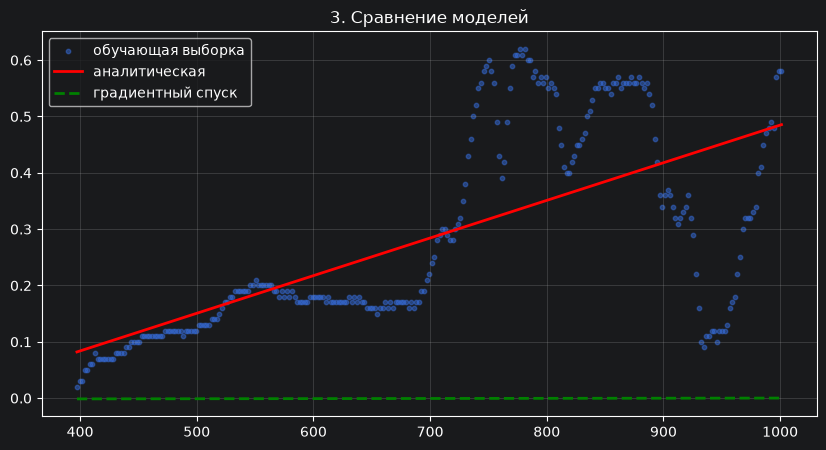


Разница коэффициентов:
Δa0 = 0.18115547
Δa1 = 0.0006657469


In [32]:
# Пересчёт коэффициентов в исходный масштаб
a1_gd = regr.a1 / x_std
a0_gd = regr.a0 - a1_gd * x_mean

print(f"a0_gd = {a0_gd:.6f}")
print(f"a1_gd = {a1_gd:.8f}")
print(f"MSE   = {regr.MSE(x_norm, Y):.6f}")

# Прогнозы
x_space = np.linspace(x.min(), x.max(), 200)
Y_pred_gd   = a0_gd + a1_gd * x_space
Y_pred_anal = a0_anal + a1_anal * x_space

# График сравнения
plt.figure(figsize=(10, 5))
plt.scatter(x, Y, s=10, alpha=0.5, label='обучающая выборка')
plt.plot(x_space, Y_pred_anal, 'r', lw=2, label='аналитическая')
plt.plot(x_space, Y_pred_gd, 'g--', lw=2, label='градиентный спуск')
plt.title('3. Сравнение моделей')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\nРазница коэффициентов:")
print(f"Δa0 = {abs(a0_anal - a0_gd):.8f}")
print(f"Δa1 = {abs(a1_anal - a1_gd):.10f}")